### Raw Data Visualization

This chart shows company revenue for 2023-Q1 using the original revenue dataset before any tidying or reshaping.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

revenue = pd.read_csv("../data/company_quarterly_revenue_raw.csv")
orders = pd.read_csv("../data/orders.csv")
shipments = pd.read_csv("../data/shipments.csv")

display(revenue.head())

,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


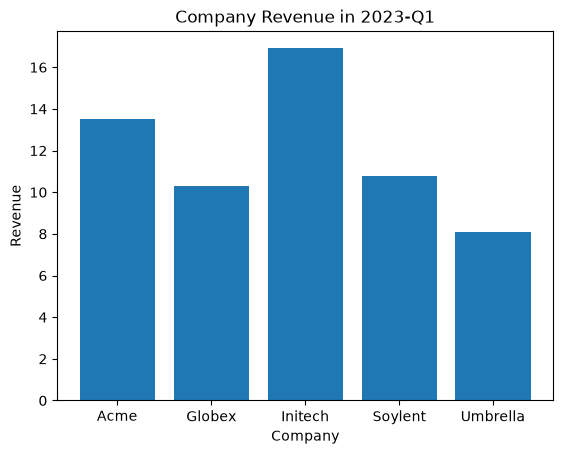

In [2]:
#Task 0
plt.bar(revenue["company"], revenue["2023-Q1"])

plt.xlabel("Company")
plt.ylabel("Revenue")
plt.title("Company Revenue in 2023-Q1")

plt.show()

In [4]:
#task 5
revenue_tidy = revenue.melt(
    id_vars="company",
    var_name="quarter",
    value_name="revenue"
)
joined_orders = orders.merge(
    shipments,
    on="order_id",
    how="left",
    validate="one_to_many"
)
final_table = joined_orders.merge(
    revenue_tidy,
    on=["company", "quarter"],
    how="left"
)

final_table = final_table.reset_index(drop=True)

display(final_table)

,order_id,customer_id,amount,company,quarter,tracking,revenue
0,O1000,C106,26,Umbrella,2024-Q4,O1000-1,10.4
1,O1001,C105,48,Umbrella,2023-Q3,O1001-1,7.7
2,O1001,C105,48,Umbrella,2023-Q3,O1001-2,7.7
3,O1002,C103,155,Globex,2025-Q2,O1002-1,13.8
4,O1003,C100,38,Acme,2023-Q4,O1003-1,16.8
5,O1003,C100,38,Acme,2023-Q4,O1003-2,16.8
6,O1004,C103,136,Globex,2023-Q3,O1004-1,9.4
7,O1004,C103,136,Globex,2023-Q3,O1004-2,9.4
8,O1004,C103,136,Globex,2023-Q3,O1004-3,9.4
9,O1005,C107,144,Soylent,2023-Q4,O1005-1,15.4


In [5]:
company_revenue = final_table[
    ["company", "quarter", "revenue"]
].drop_duplicates()

display(company_revenue)

,company,quarter,revenue
0,Umbrella,2024-Q4,10.4
1,Umbrella,2023-Q3,7.7
3,Globex,2025-Q2,13.8
4,Acme,2023-Q4,16.8
6,Globex,2023-Q3,9.4
9,Soylent,2023-Q4,15.4
12,Acme,2024-Q3,18.4
14,Umbrella,2025-Q2,11.8
17,Umbrella,2023-Q2,6.1
19,Soylent,2024-Q1,15.5


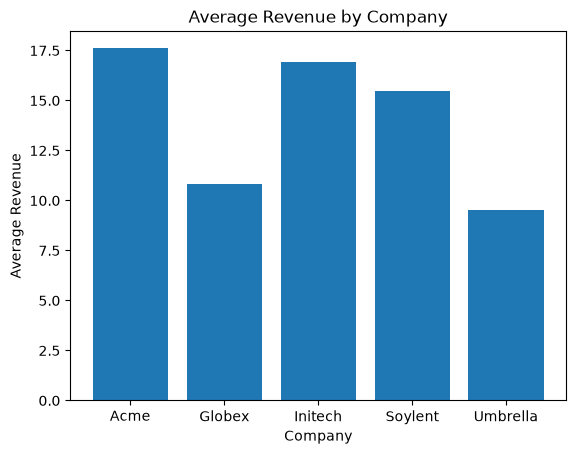

In [6]:
avg_revenue = company_revenue.groupby("company")["revenue"].mean()

plt.bar(avg_revenue.index, avg_revenue.values)

plt.xlabel("Company")
plt.ylabel("Average Revenue")
plt.title("Average Revenue by Company")

plt.show()

Step 0 vs Step 5 Visualization
- Step 0: The raw revenue data had each quarter stored in a separate column, so the graph only showed revenue for one selected quarter (2023-Q1).
- Step 5: After tidying the data, all quarters are stored in one quarter column, making it easier to analyze revenue across multiple quarters.
- The final table also combines the revenue, order, and shipment information into one dataset.
- Overall, the Step 5 visualization is easier to create because the data is organized consistently and does not require manually selecting individual quarter columns.